<a href="https://colab.research.google.com/github/BodiyaKol/hyper-spectral-object-tracking/blob/data-loading/notebooks/01_data_and_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q -U kaggle

import os
from google.colab import userdata

token = userdata.get("first").strip()

os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
token_path = os.path.expanduser("~/.kaggle/access_token")
with open(token_path, "w") as f:
    f.write(token)
os.chmod(token_path, 0o600)

!kaggle --version

Kaggle CLI 2.2.4


In [ ]:
# list competition files
!kaggle competitions files -c hyperspectral-object-tracking-challenge-2026

name                        size  creationDate                
--------------------  ----------  --------------------------  
2026training.csv         5764062  2026-06-05 09:45:53.394000  
sample_submisson.csv      671017  2026-06-05 09:45:53.323000  


In [ ]:
# download and unzip competition data
!kaggle competitions download -c hyperspectral-object-tracking-challenge-2026 -p data
!unzip -o -q data/hyperspectral-object-tracking-challenge-2026.zip -d data
!ls data

hyperspectral-object-tracking-challenge-2026.zip: Skipping, found more recently modified local copy (use --force to force download)
2026training.csv				  rgb
hyperspectral-object-tracking-challenge-2026.zip  sample_submisson.csv


In [ ]:
import pandas as pd

df = pd.read_csv("data/2026training.csv")
df.head()

,ID,x,y,width,height
0,nir-basketball1_1,210,179,15,15
1,nir-basketball1_2,208,179,16,14
2,nir-basketball1_3,208,179,16,14
3,nir-basketball1_4,208,179,16,14
4,nir-basketball1_5,202,186,16,14


In [ ]:
print("total frames:", len(df))

# -1 means the target is not visible
no_target = (df[["x", "y", "width", "height"]] == -1).any(axis=1)
print("frames without target:", no_target.sum())

total frames: 169490
frames without target: 398


In [ ]:
# get sensor and video name from id
df["sensor"] = df["ID"].str.split("-", n=1).str[0]
df["video"] = df["ID"].str.rsplit("_", n=1).str[0]

print(df.groupby("sensor")["video"].nunique())
print("total videos:", df["video"].nunique())

sensor
nir       125
rednir     73
vis       207
Name: video, dtype: int64
total videos: 405


In [ ]:
# mount google drive with the videos
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# copy one video and unzip it
!mkdir -p data/rgb
!cp "/content/drive/MyDrive/HSI-VIS-FalseColor_25/automobile4.zip" data/rgb/
!unzip -o -q data/rgb/automobile4.zip -d data/rgb
!ls data/rgb/automobile4 | head -5

0001.jpg
0002.jpg
0003.jpg
0004.jpg
0005.jpg


In [ ]:
folder = "data/rgb/automobile4"

files = sorted(os.listdir(folder))
frames = [f for f in files if f.endswith(".jpg")]

print("frames:", len(frames))
print("first / last:", frames[0], frames[-1])
print("other files:", [f for f in files if not f.endswith(".jpg")])

frames: 201
first / last: 0001.jpg 0201.jpg
other files: ['groundtruth_rect.txt']


In [ ]:
# frame -> 3d matrix (height, width, 3)
import numpy as np
from PIL import Image

img = np.array(Image.open(os.path.join(folder, frames[0])).convert("RGB"))

print("shape:", img.shape)
print("dtype:", img.dtype)
print("min / max:", img.min(), img.max())

shape: (256, 512, 3)
dtype: uint8
min / max: 6 255


In [ ]:
# normalize to [0, 1]
img_norm = img.astype(np.float32) / 255.0

print("dtype:", img_norm.dtype)
print("min / max:", img_norm.min(), img_norm.max())

dtype: float32
min / max: 0.023529412 1.0


In [ ]:
# (h, w, c) -> (c, h, w) for pytorch
img_chw = img_norm.transpose(2, 0, 1)
print(img_norm.shape, "->", img_chw.shape)

(256, 512, 3) -> (3, 256, 512)


In [ ]:
# boxes from the txt file inside the archive
gt_txt = pd.read_csv(os.path.join(folder, "groundtruth_rect.txt"),
                     sep=r"[,\s]+", header=None, engine="python")
gt_txt = gt_txt.iloc[:, :4]  # drop extra column if a line ends with a separator
gt_txt.columns = ["x", "y", "width", "height"]

# boxes from the kaggle csv
# the number after "_" is a global row index, not the frame number, so just sort
boxes = df[df["video"] == "vis-automobile4"].copy()
boxes["num"] = boxes["ID"].str.rsplit("_", n=1).str[1].astype(int)
boxes = boxes.sort_values("num").reset_index(drop=True)

print("txt:", len(gt_txt), "| csv:", len(boxes), "| frames:", len(frames))
print("txt and csv match:", np.allclose(gt_txt.values, boxes[["x", "y", "width", "height"]].values))

txt: 201 | csv: 201 | frames: 201
txt and csv match: True


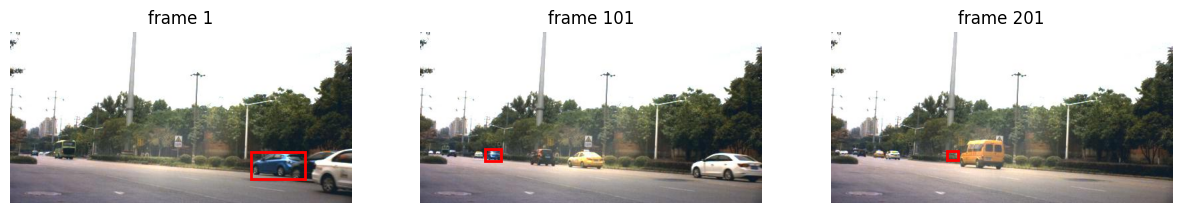

In [ ]:
# draw boxes on first, middle and last frame
import matplotlib.pyplot as plt
import matplotlib.patches as patches

idxs = [0, len(frames) // 2, len(frames) - 1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i in zip(axes, idxs):
    frame = np.array(Image.open(os.path.join(folder, frames[i])).convert("RGB"))
    ax.imshow(frame)

    x, y, w, h = boxes.loc[i, ["x", "y", "width", "height"]]
    if w > 0 and h > 0:  # skip frames without target
        rect = patches.Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=2)
        ax.add_patch(rect)

    ax.set_title(f"frame {i + 1}")
    ax.axis("off")

plt.show()

In [ ]:
def load_frame(path):
    # frame -> (3, h, w) float32 in [0, 1]
    img = np.array(Image.open(path).convert("RGB"))
    img = img.astype(np.float32) / 255.0
    return img.transpose(2, 0, 1)


test = load_frame(os.path.join(folder, frames[0]))
print(test.shape, test.dtype, test.min(), test.max())

# stack first 10 frames into one array (frames, c, h, w)
video = np.stack([load_frame(os.path.join(folder, f)) for f in frames[:10]])
print("video:", video.shape)

(3, 256, 512) float32 0.023529412 1.0
video: (10, 3, 256, 512)
